In [1]:

import pandas as pd
import numpy as np

# Load the three NCRB tables
crime_2022 = pd.read_csv("table_005.csv")
crime_2023 = pd.read_csv("table_005(1).csv")
crime_2024 = pd.read_csv("table_005(2).csv")

# Check the size of each dataset
print("2022 report:", crime_2022.shape)
print("2023 report:", crime_2023.shape)
print("2024 report:", crime_2024.shape)

# Display the latest report
crime_2024.head()


2022 report: (41, 8)
2023 report: (41, 8)
2024 report: (41, 8)


,SL,State/UT,2022,2023,2024,Mid-Year Projected Population (in Lakhs) (2024),Rate of Cognizable Crimes (IPC/BNS+SLL),Chargesheeti ng Rate (2024)
0,STATES:,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Andhra Pradesh,195284.0,184293.0,168788.0,534.0,316.1,90.7
2,2,Arunachal Pradesh,2761.0,2941.0,2910.0,15.8,184.2,59.4
3,3,Assam,68937.0,64959.0,49552.0,361.6,137.0,67.1
4,4,Bihar,347835.0,353502.0,352155.0,1292.1,272.6,81.3


In [2]:

print("Column names:")
print(crime_2024.columns.tolist())

print("\nMissing values:")
print(crime_2024.isnull().sum())

print("\nTamil Nadu record:")
print(
    crime_2024[
        crime_2024["State/UT"] == "Tamil Nadu"
    ]
)


Column names:
['SL', 'State/UT', '2022', '2023', '2024', 'Mid-Year Projected Population (in Lakhs) (2024)', 'Rate of Cognizable Crimes (IPC/BNS+SLL)', 'Chargesheeti ng Rate (2024)']

Missing values:
SL                                                 3
State/UT                                           1
2022                                               2
2023                                               2
2024                                               2
Mid-Year Projected Population (in Lakhs) (2024)    2
Rate of Cognizable Crimes (IPC/BNS+SLL)            2
Chargesheeti ng Rate (2024)                        2
dtype: int64

Tamil Nadu record:
    SL    State/UT      2022      2023      2024  \
23  23  Tamil Nadu  473456.0  539651.0  505754.0   

    Mid-Year Projected Population (in Lakhs) (2024)  \
23                                            771.7   

    Rate of Cognizable Crimes (IPC/BNS+SLL)  Chargesheeti ng Rate (2024)  
23                                    655.4          

In [3]:

# Keep actual state/UT records only
def clean_states(df):
    return df[
        df["State/UT"].notna()
        & ~df["State/UT"].str.startswith("TOTAL", na=False)
        & ~df["State/UT"].isin(["STATES:", "TERRITORIES:"])
    ].copy()

d22 = clean_states(crime_2022)
d23 = clean_states(crime_2023)
d24 = clean_states(crime_2024)

# Build a common state/year structure
parts = []

# 2020: available in the 2022 report
parts.append(d22[["State/UT", "2020"]].rename(
    columns={"2020": "Crime_Count"}
).assign(Year=2020))

# 2021: use the 2023 report
parts.append(d23[["State/UT", "2021"]].rename(
    columns={"2021": "Crime_Count"}
).assign(Year=2021))

# 2022 and 2023: use the 2023 report
for year in [2022, 2023]:
    parts.append(d23[["State/UT", str(year)]].rename(
        columns={str(year): "Crime_Count"}
    ).assign(Year=year))

# 2024: use the 2024 report
parts.append(d24[["State/UT", "2024"]].rename(
    columns={"2024": "Crime_Count"}
).assign(Year=2024))

crime_combined = pd.concat(parts, ignore_index=True)

# Arrange the columns and rows
crime_combined = crime_combined[
    ["State/UT", "Year", "Crime_Count"]
].sort_values(["State/UT", "Year"])

print(crime_combined.head(10))
print("\nDataset shape:", crime_combined.shape)


           State/UT  Year  Crime_Count
28      A&N Islands  2020       2542.0
64      A&N Islands  2021       1332.0
100     A&N Islands  2022       1589.0
136     A&N Islands  2023       1873.0
172     A&N Islands  2024       1697.0
0    Andhra Pradesh  2020     238105.0
36   Andhra Pradesh  2021     222199.0
72   Andhra Pradesh  2022     195284.0
108  Andhra Pradesh  2023     184293.0
144  Andhra Pradesh  2024     168788.0

Dataset shape: (180, 3)


In [4]:

print("Years available:")
print(sorted(crime_combined["Year"].unique()))

print("\nRecords per year:")
print(crime_combined.groupby("Year").size())

print("\nDuplicate state-year records:")
print(
    crime_combined.duplicated(
        subset=["State/UT", "Year"]
    ).sum()
)

print("\nTamil Nadu trend:")
print(
    crime_combined[
        crime_combined["State/UT"] == "Tamil Nadu"
    ]
)


Years available:
[np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Records per year:
Year
2020    36
2021    36
2022    36
2023    36
2024    36
dtype: int64

Duplicate state-year records:
0

Tamil Nadu trend:
       State/UT  Year  Crime_Count
22   Tamil Nadu  2020    1377681.0
58   Tamil Nadu  2021     756753.0
94   Tamil Nadu  2022     473456.0
130  Tamil Nadu  2023     539651.0
166  Tamil Nadu  2024     505754.0


In [5]:

def compare_reports(df_old, df_new, year):
    year = str(year)

    old = clean_states(df_old)[["State/UT", year]].copy()
    new = clean_states(df_new)[["State/UT", year]].copy()

    old[year] = pd.to_numeric(old[year], errors="coerce")
    new[year] = pd.to_numeric(new[year], errors="coerce")

    comparison = old.merge(
        new,
        on="State/UT",
        suffixes=("_old", "_new")
    )

    old_col = f"{year}_old"
    new_col = f"{year}_new"

    comparison["Difference"] = (
        comparison[new_col] - comparison[old_col]
    )

    print(f"\nComparison for {year}")
    print("States compared:", len(comparison))
    print("Exact matches:", (comparison["Difference"] == 0).sum())
    print("Different values:", (comparison["Difference"] != 0).sum())

    return comparison[
        comparison["Difference"] != 0
    ][["State/UT", old_col, new_col, "Difference"]]

compare_2022 = compare_reports(crime_2022, crime_2023, 2022)
compare_2023 = compare_reports(crime_2023, crime_2024, 2023)

print("\nDifferences in 2022:")
display(compare_2022)

print("\nDifferences in 2023:")
display(compare_2023)



Comparison for 2022
States compared: 36
Exact matches: 36
Different values: 0

Comparison for 2023
States compared: 36
Exact matches: 36
Different values: 0

Differences in 2022:


,State/UT,2022_old,2022_new,Difference



Differences in 2023:


,State/UT,2023_old,2023_new,Difference


   Year  Crime_Count
0  2020    6601285.0
1  2021    6096310.0
2  2022    5824946.0
3  2023    6241569.0
4  2024    5885867.0


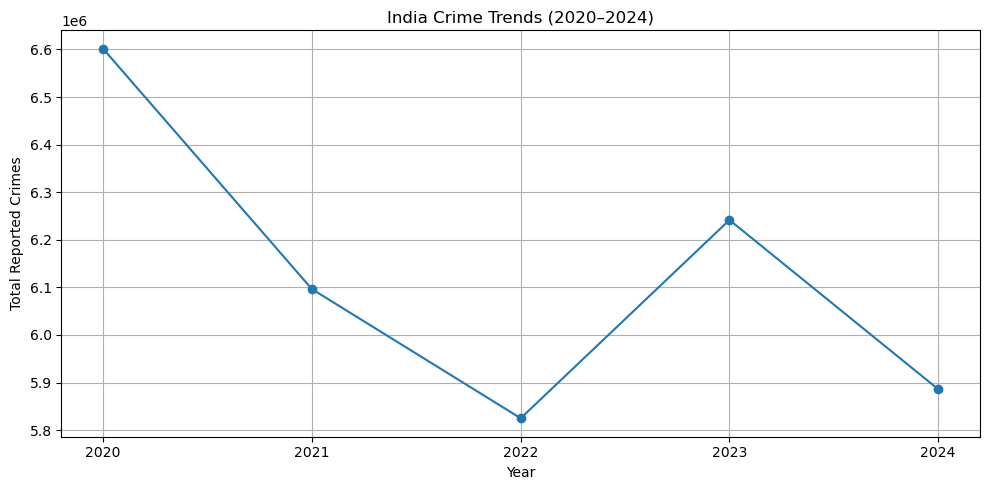

In [6]:

import matplotlib.pyplot as plt

# Calculate total reported crimes for each year
india_yearly = (
    crime_combined
    .groupby("Year")["Crime_Count"]
    .sum()
    .reset_index()
)

print(india_yearly)

# Plot the yearly trend
plt.figure(figsize=(10, 5))
plt.plot(
    india_yearly["Year"],
    india_yearly["Crime_Count"],
    marker="o"
)

plt.title("India Crime Trends (2020–2024)")
plt.xlabel("Year")
plt.ylabel("Total Reported Crimes")
plt.xticks(india_yearly["Year"])
plt.grid(True)
plt.tight_layout()
plt.show()


In [7]:

# Select data for 2024
latest_data = crime_combined[
    crime_combined["Year"] == 2024
].copy()

# Ensure crime counts are numeric
latest_data["Crime_Count"] = pd.to_numeric(
    latest_data["Crime_Count"],
    errors="coerce"
)

# Sort from highest to lowest
latest_data = latest_data.sort_values(
    by="Crime_Count",
    ascending=False
).reset_index(drop=True)

# Assign rankings
latest_data["Rank"] = range(1, len(latest_data) + 1)

# Display the top 10
print("Top 10 States/UTs by Reported Crime Counts (2024)")
display(
    latest_data[
        ["Rank", "State/UT", "Crime_Count"]
    ].head(10)
)

# Find Tamil Nadu's ranking
print("\nTamil Nadu Ranking:")
display(
    latest_data[
        latest_data["State/UT"] == "Tamil Nadu"
    ][["Rank", "State/UT", "Crime_Count"]]
)


Top 10 States/UTs by Reported Crime Counts (2024)


,Rank,State/UT,Crime_Count
0,1,Uttar Pradesh,708399.0
1,2,Gujarat,615407.0
2,3,Maharashtra,609823.0
3,4,Tamil Nadu,505754.0
4,5,Kerala,499567.0
5,6,Madhya Pradesh,434879.0
6,7,Bihar,352155.0
7,8,Delhi,297666.0
8,9,Rajasthan,297552.0
9,10,Telangana,217976.0



Tamil Nadu Ranking:


,Rank,State/UT,Crime_Count
3,4,Tamil Nadu,505754.0


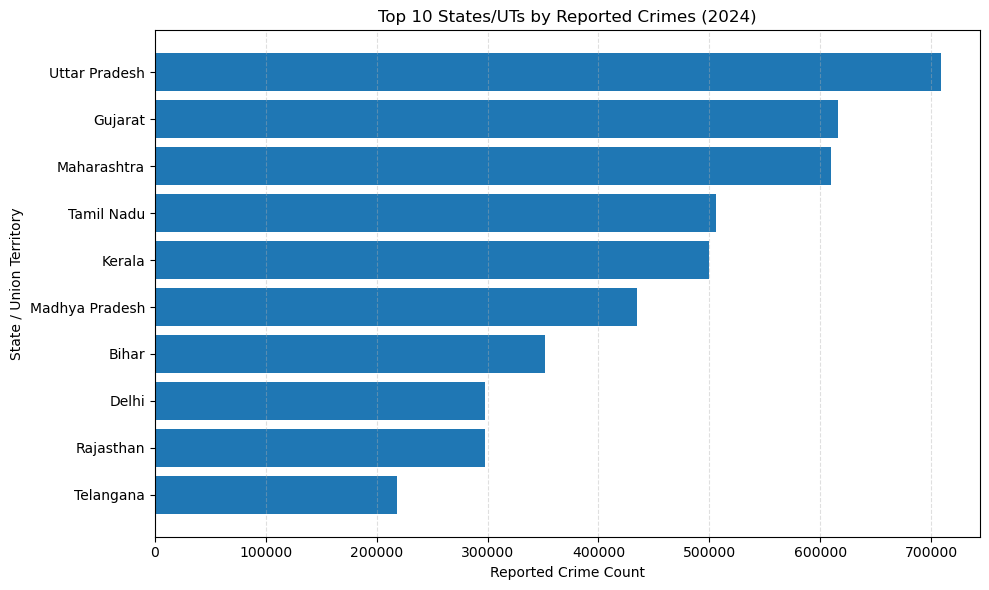

In [8]:

import matplotlib.pyplot as plt

# Select the top 10 states/UTs
top_10 = latest_data.head(10).copy()

# Reverse the order so the highest value appears at the top
top_10 = top_10.sort_values(
    "Crime_Count",
    ascending=True
)

# Create the horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10["State/UT"],
    top_10["Crime_Count"]
)

plt.title("Top 10 States/UTs by Reported Crimes (2024)")
plt.xlabel("Reported Crime Count")
plt.ylabel("State / Union Territory")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [9]:

# Find the top 5 states/UTs for each year

for year in sorted(crime_combined["Year"].unique()):
    yearly_data = crime_combined[
        crime_combined["Year"] == year
    ].sort_values(
        "Crime_Count",
        ascending=False
    )

    print(f"\nTop 5 States/UTs - {year}")

    display(
        yearly_data[
            ["State/UT", "Crime_Count"]
        ].head(5).reset_index(drop=True)
    )



Top 5 States/UTs - 2020


,State/UT,Crime_Count
0,Tamil Nadu,1377681.0
1,Gujarat,699619.0
2,Uttar Pradesh,657925.0
3,Kerala,554724.0
4,Maharashtra,539003.0



Top 5 States/UTs - 2021


,State/UT,Crime_Count
0,Tamil Nadu,756753.0
1,Gujarat,731738.0
2,Uttar Pradesh,608082.0
3,Maharashtra,540800.0
4,Kerala,524960.0



Top 5 States/UTs - 2022


,State/UT,Crime_Count
0,Uttar Pradesh,753675.0
1,Maharashtra,557012.0
2,Gujarat,524103.0
3,Madhya Pradesh,488966.0
4,Tamil Nadu,473456.0



Top 5 States/UTs - 2023


,State/UT,Crime_Count
0,Uttar Pradesh,793020.0
1,Maharashtra,596103.0
2,Kerala,584373.0
3,Gujarat,578879.0
4,Tamil Nadu,539651.0



Top 5 States/UTs - 2024


,State/UT,Crime_Count
0,Uttar Pradesh,708399.0
1,Gujarat,615407.0
2,Maharashtra,609823.0
3,Tamil Nadu,505754.0
4,Kerala,499567.0


In [10]:
compare_2021 = compare_reports(
    crime_2022,
    crime_2023,
    2021
)

print("Differences in 2021:")
display(compare_2021)


Comparison for 2021
States compared: 36
Exact matches: 36
Different values: 0
Differences in 2021:


,State/UT,2021_old,2021_new,Difference


In [11]:

# Calculate each state's rank within each year
crime_combined["Rank"] = (
    crime_combined.groupby("Year")["Crime_Count"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Select Tamil Nadu's records
tn_trend = crime_combined[
    crime_combined["State/UT"] == "Tamil Nadu"
].sort_values("Year")

print("Tamil Nadu Crime Ranking (2020–2024)")
display(
    tn_trend[["Year", "State/UT", "Crime_Count", "Rank"]]
)


Tamil Nadu Crime Ranking (2020–2024)


,Year,State/UT,Crime_Count,Rank
22,2020,Tamil Nadu,1377681.0,1
58,2021,Tamil Nadu,756753.0,1
94,2022,Tamil Nadu,473456.0,5
130,2023,Tamil Nadu,539651.0,5
166,2024,Tamil Nadu,505754.0,4


In [12]:

# Inspect the index files to find the official table titles

index_files = [
    "index.csv",
    "index(1).csv",
    "index(2).csv"
]

for file in index_files:
    try:
        index_df = pd.read_csv(file)

        print("\nIndex file:", file)
        print("Available columns:", index_df.columns.tolist())

        # Display rows that mention table 005
        table_info = index_df[
            index_df.astype(str).apply(
                lambda col: col.str.contains(
                    "table_005|Table 5|table 5",
                    case=False,
                    na=False
                )
            ).any(axis=1)
        ]

        display(table_info)

    except FileNotFoundError:
        print(f"{file} not found in the notebook folder.")



Index file: index.csv
Available columns: ['Table Number', 'Original Table Title', 'Volume', 'CSV File Name']


,Table Number,Original Table Title,Volume,CSV File Name
4,1A.3,Total IPC & SLL Crimes (State/UT-wise) - 2020-...,Book 1,table_005.csv



Index file: index(1).csv
Available columns: ['Table Number', 'Original Table Title', 'Volume', 'CSV File Name']


,Table Number,Original Table Title,Volume,CSV File Name
4,1A.3,Total IPC & SLL Crimes (State/UT-wise) - 2021-...,Part I,table_005.csv



Index file: index(2).csv
Available columns: ['Table Number', 'Original Table Title', 'Volume', 'CSV File Name']


,Table Number,Original Table Title,Volume,CSV File Name
4,1A.3,Total IPC/BNS & SLL Crimes (State/UT-wise) - 2...,Volume I,table_005.csv


In [13]:

# Check the structure of all three original reports

for name, df in [
    ("2022 report", crime_2022),
    ("2023 report", crime_2023),
    ("2024 report", crime_2024)
]:
    print("\n", name)
    print("Columns:", df.columns.tolist())

    tn = df[
        df["State/UT"].astype(str).str.strip()
        == "Tamil Nadu"
    ]

    display(tn)



 2022 report
Columns: ['SL', 'State/UT', '2020', '2021', '2022', 'Mid-Year Projected Population (in Lakhs) (2022)', 'Rate of Cognizable Crimes (IPC+SLL)', 'Chargesheeti ng Rate (2022)']


,SL,State/UT,2020,2021,2022,Mid-Year Projected Population (in Lakhs) (2022),Rate of Cognizable Crimes (IPC+SLL),Chargesheeti ng Rate (2022)
23,23,Tamil Nadu,1377681.0,756753.0,473456.0,767.1,617.2,77.5



 2023 report
Columns: ['SL', 'State/UT', '2021', '2022', '2023', 'Mid-Year Projected Population (in Lakhs) (2023)', 'Rate of Cognizable Crimes Rate (IPC+SLL)', 'Chargesheeting (2023)']


,SL,State/UT,2021,2022,2023,Mid-Year Projected Population (in Lakhs) (2023),Rate of Cognizable Crimes Rate (IPC+SLL),Chargesheeting (2023)
23,23,Tamil Nadu,756753.0,473456.0,539651.0,769.4,701.4,85.7



 2024 report
Columns: ['SL', 'State/UT', '2022', '2023', '2024', 'Mid-Year Projected Population (in Lakhs) (2024)', 'Rate of Cognizable Crimes (IPC/BNS+SLL)', 'Chargesheeti ng Rate (2024)']


,SL,State/UT,2022,2023,2024,Mid-Year Projected Population (in Lakhs) (2024),Rate of Cognizable Crimes (IPC/BNS+SLL),Chargesheeti ng Rate (2024)
23,23,Tamil Nadu,473456.0,539651.0,505754.0,771.7,655.4,84.7


In [14]:

def validate_rate(df, year, population_col, rate_col):
    data = df[
        df["State/UT"].astype(str).str.strip() == "Tamil Nadu"
    ].copy()

    count = pd.to_numeric(
        data[str(year)], errors="coerce"
    ).iloc[0]

    population_lakhs = pd.to_numeric(
        data[population_col], errors="coerce"
    ).iloc[0]

    published_rate = pd.to_numeric(
        data[rate_col], errors="coerce"
    ).iloc[0]

    # Correct formula: population is already in lakhs
    calculated_rate = count / population_lakhs

    print(f"\nTamil Nadu — {year}")
    print("Published rate:", published_rate)
    print("Calculated rate:", round(calculated_rate, 1))
    print("Difference:", round(calculated_rate - published_rate, 1))


validate_rate(
    crime_2022, 2022,
    "Mid-Year Projected Population (in Lakhs) (2022)",
    "Rate of Cognizable Crimes (IPC+SLL)"
)

validate_rate(
    crime_2023, 2023,
    "Mid-Year Projected Population (in Lakhs) (2023)",
    "Rate of Cognizable Crimes Rate (IPC+SLL)"
)

validate_rate(
    crime_2024, 2024,
    "Mid-Year Projected Population (in Lakhs) (2024)",
    "Rate of Cognizable Crimes (IPC/BNS+SLL)"
)



Tamil Nadu — 2022
Published rate: 617.2
Calculated rate: 617.2
Difference: 0.0

Tamil Nadu — 2023
Published rate: 701.4
Calculated rate: 701.4
Difference: -0.0

Tamil Nadu — 2024
Published rate: 655.4
Calculated rate: 655.4
Difference: -0.0


In [15]:

# Tamil Nadu published crime rates
tn_rates = pd.DataFrame({
    "Year": [2022, 2023, 2024],
    "Crime_Rate": [617.2, 701.4, 655.4]
})

# Calculate year-on-year percentage change
tn_rates["Change_Percent"] = (
    tn_rates["Crime_Rate"].pct_change() * 100
)

display(tn_rates.round(2))


,Year,Crime_Rate,Change_Percent
0,2022,617.2,NaN
1,2023,701.4,13.64
2,2024,655.4,-6.56


In [16]:

# Prepare the 2024 state/UT data
rate_col = "Rate of Cognizable Crimes (IPC/BNS+SLL)"

state_rates_2024 = clean_states(crime_2024).copy()

# Convert crime counts and published rates to numeric values
state_rates_2024["2024"] = pd.to_numeric(
    state_rates_2024["2024"], errors="coerce"
)

state_rates_2024[rate_col] = pd.to_numeric(
    state_rates_2024[rate_col], errors="coerce"
)

# Sort by published crime rate, highest first
state_rates_2024 = state_rates_2024.dropna(
    subset=[rate_col]
).sort_values(
    rate_col, ascending=False
).reset_index(drop=True)

state_rates_2024["Rate_Rank"] = (
    range(1, len(state_rates_2024) + 1)
)

print("Top 10 States/UTs by Published Crime Rate (2024)")

display(
    state_rates_2024[
        ["Rate_Rank", "State/UT", rate_col, "2024"]
    ].head(10)
)

print("\nTamil Nadu's 2024 crime-rate ranking:")

display(
    state_rates_2024[
        state_rates_2024["State/UT"] == "Tamil Nadu"
    ][["Rate_Rank", "State/UT", rate_col, "2024"]]
)


Top 10 States/UTs by Published Crime Rate (2024)


,Rate_Rank,State/UT,Rate of Cognizable Crimes (IPC/BNS+SLL),2024
0,1,Kerala,1389.0,499567.0
1,2,Delhi,1360.2,297666.0
2,3,Gujarat,847.0,615407.0
3,4,Tamil Nadu,655.4,505754.0
4,5,Haryana,578.6,177595.0
5,6,Telangana,568.9,217976.0
6,7,Madhya Pradesh,494.4,434879.0
7,8,Maharashtra,477.6,609823.0
8,9,Odisha,458.8,214113.0
9,10,A&N Islands,420.0,1697.0



Tamil Nadu's 2024 crime-rate ranking:


,Rate_Rank,State/UT,Rate of Cognizable Crimes (IPC/BNS+SLL),2024
3,4,Tamil Nadu,655.4,505754.0


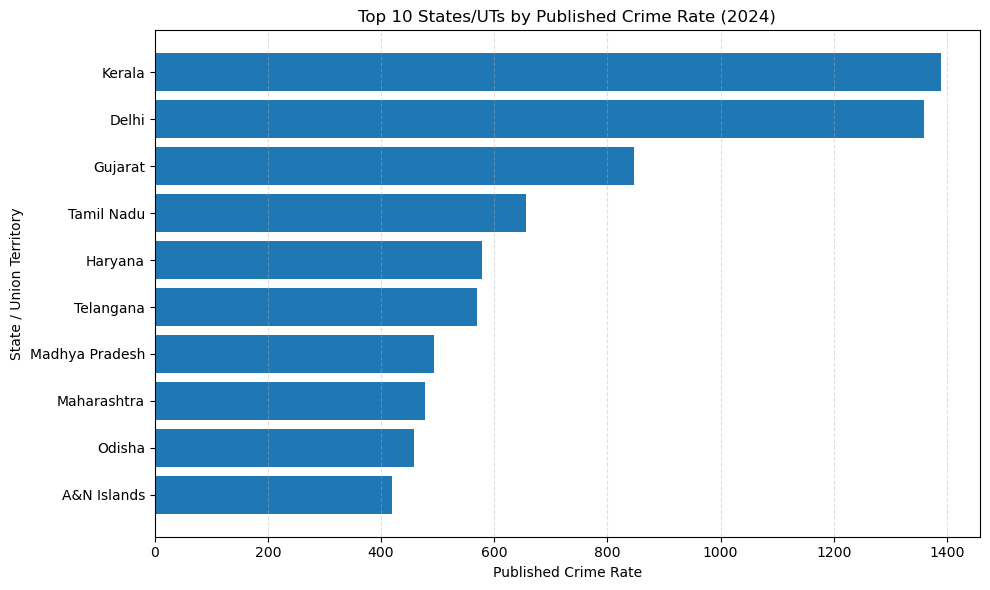

In [17]:

import matplotlib.pyplot as plt

rate_col = "Rate of Cognizable Crimes (IPC/BNS+SLL)"

top_10_rates = state_rates_2024.head(10).sort_values(
    rate_col,
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_rates["State/UT"],
    top_10_rates[rate_col]
)

plt.title("Top 10 States/UTs by Published Crime Rate (2024)")
plt.xlabel("Published Crime Rate")
plt.ylabel("State / Union Territory")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [18]:

# Validate published 2024 crime rates for all states/UTs

population_col = "Mid-Year Projected Population (in Lakhs) (2024)"
rate_col = "Rate of Cognizable Crimes (IPC/BNS+SLL)"

rate_check = clean_states(crime_2024).copy()

# Convert values to numeric
rate_check["2024"] = pd.to_numeric(
    rate_check["2024"], errors="coerce"
)

rate_check[population_col] = pd.to_numeric(
    rate_check[population_col], errors="coerce"
)

rate_check[rate_col] = pd.to_numeric(
    rate_check[rate_col], errors="coerce"
)

# Calculate the rate from count and population
rate_check["Calculated_Rate"] = (
    rate_check["2024"] / rate_check[population_col]
)

# Compare with the published rate
rate_check["Rate_Difference"] = (
    rate_check["Calculated_Rate"] - rate_check[rate_col]
)

# Display the validation results
display(
    rate_check[
        [
            "State/UT",
            "2024",
            population_col,
            rate_col,
            "Calculated_Rate",
            "Rate_Difference"
        ]
    ].round(2)
)

# Count records with differences greater than 0.2
mismatches = rate_check[
    rate_check["Rate_Difference"].abs() > 0.2
]

print("\nRecords with rate differences greater than 0.2:",
      len(mismatches))

display(
    mismatches[
        ["State/UT", rate_col, "Calculated_Rate", "Rate_Difference"]
    ]
)


,State/UT,2024,Mid-Year Projected Population (in Lakhs) (2024),Rate of Cognizable Crimes (IPC/BNS+SLL),Calculated_Rate,Rate_Difference
1,Andhra Pradesh,168788.0,534.0,316.1,316.08,-0.02
2,Arunachal Pradesh,2910.0,15.8,184.2,184.18,-0.02
3,Assam,49552.0,361.6,137.0,137.04,0.04
4,Bihar,352155.0,1292.1,272.6,272.54,-0.06
5,Chhattisgarh,114658.0,306.4,374.2,374.21,0.01
6,Goa,3297.0,15.9,208.0,207.36,-0.64
7,Gujarat,615407.0,726.5,847.0,847.08,0.08
8,Haryana,177595.0,306.9,578.6,578.67,0.07
9,Himachal Pradesh,17915.0,75.2,238.3,238.23,-0.07
10,Jharkhand,60999.0,401.3,152.0,152.00,0.00



Records with rate differences greater than 0.2: 9


,State/UT,Rate of Cognizable Crimes (IPC/BNS+SLL),Calculated_Rate,Rate_Difference
6,Goa,208.0,207.358491,-0.641509
17,Mizoram,283.7,284.160000,0.460000
22,Sikkim,99.1,98.714286,-0.385714
31,A&N Islands,420.0,424.250000,4.250000
32,Chandigarh,326.3,325.520000,-0.780000
34,Delhi,1360.2,1360.447898,0.247898
36,Ladakh,179.1,180.333333,1.233333
37,Lakshadweep,121.7,120.000000,-1.700000
38,Puducherry,324.4,323.411765,-0.988235


In [19]:

# Inspect records needing rate validation

display(
    mismatches[
        [
            "State/UT",
            "2024",
            population_col,
            rate_col,
            "Calculated_Rate",
            "Rate_Difference"
        ]
    ].sort_values(
        "Rate_Difference",
        key=lambda s: s.abs(),
        ascending=False
    ).round(3)
)


,State/UT,2024,Mid-Year Projected Population (in Lakhs) (2024),Rate of Cognizable Crimes (IPC/BNS+SLL),Calculated_Rate,Rate_Difference
31,A&N Islands,1697.0,4.0,420.0,424.250,4.250
37,Lakshadweep,84.0,0.7,121.7,120.000,-1.700
36,Ladakh,541.0,3.0,179.1,180.333,1.233
38,Puducherry,5498.0,17.0,324.4,323.412,-0.988
32,Chandigarh,4069.0,12.5,326.3,325.520,-0.780
6,Goa,3297.0,15.9,208.0,207.358,-0.642
17,Mizoram,3552.0,12.5,283.7,284.160,0.460
22,Sikkim,691.0,7.0,99.1,98.714,-0.386
34,Delhi,297666.0,218.8,1360.2,1360.448,0.248


In [20]:

# Add a data-quality status without changing source values

rate_check["Validation_Status"] = np.where(
    rate_check["Rate_Difference"].abs() > 0.2,
    "Needs verification",
    "Within tolerance"
)

print("Validation summary:")
display(
    rate_check["Validation_Status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Records")
)

print("\nTamil Nadu validation:")
display(
    rate_check[
        rate_check["State/UT"] == "Tamil Nadu"
    ][
        [
            "State/UT",
            "2024",
            rate_col,
            "Calculated_Rate",
            "Rate_Difference",
            "Validation_Status"
        ]
    ].round(3)
)


Validation summary:


,Status,Records
0,Within tolerance,27
1,Needs verification,9



Tamil Nadu validation:


,State/UT,2024,Rate of Cognizable Crimes (IPC/BNS+SLL),Calculated_Rate,Rate_Difference,Validation_Status
23,Tamil Nadu,505754.0,655.4,655.376,-0.024,Within tolerance


In [21]:

# Prepare the final crime-count dataset for SQL

crime_final = crime_combined.copy()

# Standardize column names
crime_final = crime_final.rename(
    columns={
        "State/UT": "State_UT",
        "Crime_Count": "Reported_Crime_Count"
    }
)

# Convert numeric columns
crime_final["Year"] = pd.to_numeric(
    crime_final["Year"], errors="coerce"
)

crime_final["Reported_Crime_Count"] = pd.to_numeric(
    crime_final["Reported_Crime_Count"], errors="coerce"
)

# Remove unusable records and duplicates
crime_final = crime_final.dropna(
    subset=["State_UT", "Year", "Reported_Crime_Count"]
)

crime_final = crime_final.drop_duplicates(
    subset=["State_UT", "Year"]
)

crime_final["Year"] = crime_final["Year"].astype(int)

# Sort and inspect
crime_final = crime_final.sort_values(
    ["Year", "State_UT"]
).reset_index(drop=True)

print("Dataset shape:", crime_final.shape)
print("\nYears:", sorted(crime_final["Year"].unique()))
print("\nMissing values:")
print(crime_final.isnull().sum())

print("\nDuplicate state-year records:",
      crime_final.duplicated(["State_UT", "Year"]).sum())

display(crime_final.head(10))


Dataset shape: (180, 4)

Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Missing values:
State_UT                0
Year                    0
Reported_Crime_Count    0
Rank                    0
dtype: int64

Duplicate state-year records: 0


,State_UT,Year,Reported_Crime_Count,Rank
0,A&N Islands,2020,2542.0,29
1,Andhra Pradesh,2020,238105.0,10
2,Arunachal Pradesh,2020,2503.0,30
3,Assam,2020,121609.0,16
4,Bihar,2020,257512.0,9
5,Chandigarh,2020,3254.0,27
6,Chhattisgarh,2020,103173.0,17
7,D&N Haveli and Daman & Diu,2020,533.0,34
8,Delhi,2020,266070.0,7
9,Goa,2020,4366.0,25


In [22]:

# Export the cleaned crime dataset

output_file = "india_crime_cleaned_2020_2024.csv"

crime_final.to_csv(output_file, index=False)

print("Dataset exported successfully!")
print("File name:", output_file)
print("Rows exported:", len(crime_final))
print("Columns:", crime_final.columns.tolist())


Dataset exported successfully!
File name: india_crime_cleaned_2020_2024.csv
Rows exported: 180
Columns: ['State_UT', 'Year', 'Reported_Crime_Count', 'Rank']
